# Build training-ready datasets

Turns the graphs from `BEG_02_Graphs` into the ten packages `BEG_04_Train` trains on: one
`training_ready.pt` per configuration, every one of them carrying the *same* models under the *same*
train/validation/test split.

That sameness is the experiment. The ten configurations differ only in how a building is described,
so a difference in accuracy between them is attributable to the representation — but only if nothing
else differs. One split is therefore computed once and reused by all ten, and the notebook checks
afterwards that each package really did receive it.

This notebook holds decisions: which label, which seed, which fractions, which configuration stands
in for building size. Mechanism lives in `beg.datasets.tools` and `beg.report.dataset_plots`.

**What it produces**

```
outputs/pyg_datasets/<Cn_name>/training_ready.pt        the package BEG_04_Train loads
outputs/pyg_datasets/<Cn_name>/training_ready.meta.json what it fingerprints
outputs/pyg_datasets/<Cn_name>/graph_sizes.csv          per-graph node and edge counts
outputs/dataset_diagnostics/*.csv                       the split audit tables
outputs/figures/dataset/*.png                           the split quality figures
data/labels_with_split.csv                              labels, with the split each model landed in
```

**Before running**

- `BEG_02_Graphs` must have completed for every configuration; the first cells stop otherwise.
- Rerunning is cheap: a package whose configuration, split and labels are unchanged is reused.

**Environment.** `pip install -e ".[notebooks,train]" matplotlib` installs what this notebook needs, and `pip install -e ".[all]"` what all five need. The first cell checks and prints the command for anything missing; `beg doctor` does the same for every notebook at once.

# Run settings

### Configure the run

**Inputs**: the manifests under `outputs/pyg_graphs/`, `data/labels.csv`, and the EPW headers in
`data/weather/epw/`.

**Steps**
1. Choose the label column, the split seed and the three fractions.
2. Choose the configuration whose graph size stands for building size in the balance report.
3. Resolve the ten configurations through `beg.config.naming`.

**Outputs**
- `CONFIGS`, `LABEL_COL`, `SPLIT_SEED`, the fractions, and the paths the later cells read.

**Used functions**
`beg.requirements.check_environment`, `beg.config.naming.resolve`, `beg.config.naming.sort_key`, `beg.settings.output_dir`

In [1]:
from beg.requirements import check_environment

check_environment("BEG_03_Datasets")  # names anything missing, and the pip command that adds it

import warnings

import pandas as pd
from IPython.display import display

# Import-time warnings unrelated to this pipeline (tqdm without ipywidgets, torch.jit)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")

from beg.config.naming import CONFIG_ORDER, resolve, sort_key
from beg.settings import data_dir, display_path, output_dir

# --- what to build ----------------------------------------------------------
CONFIGS = list(CONFIG_ORDER)          # all ten; narrow to e.g. ["C1", "C3"] while developing
LABEL_COL = "eui_kwh_per_m2"          # the target, as named in data/labels.csv

# --- how to split -----------------------------------------------------------
# Every configuration receives this split; changing any of these invalidates
# every completed run in outputs/GNNruns.
SPLIT_SEED = 1234
TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION = 0.70, 0.10, 0.20

# Building size is reported on one configuration, because the same building has
# ~10 nodes as a zone graph and ~100 as a component graph.
REPRESENTATIVE_SIZE_CONFIG = "C6_component_homo_no_weather"
REPRESENTATIVE_SIZE_NAME = "component_num_nodes"

# --- rebuilding -------------------------------------------------------------
FORCE_REBUILD_PACKAGES = False        # rewrite every training_ready.pt, ignoring what is on disk

GRAPHS_ROOT = output_dir() / "pyg_graphs"
DATASETS_OUT = output_dir() / "pyg_datasets"
DIAGNOSTICS_DIR = output_dir() / "dataset_diagnostics"
FIGURES_DIR = output_dir() / "figures" / "dataset"
# Figures and tables the manuscript embeds, under the names it uses.
PAPER_FIGURES_DIR = output_dir() / "paper" / "figures"
PAPER_TABLES_DIR = output_dir() / "paper" / "tables"
LABELS_CSV = data_dir() / "labels.csv"
EPW_DIR = data_dir() / "weather" / "epw"

for path in (DATASETS_OUT, DIAGNOSTICS_DIR, FIGURES_DIR, PAPER_FIGURES_DIR, PAPER_TABLES_DIR):
    path.mkdir(parents=True, exist_ok=True)

CONFIGS = sorted(CONFIGS, key=sort_key)
FULL_NAMES = [resolve(c).full_name for c in CONFIGS]

settings = pd.DataFrame(
    [
        {"setting": "configurations", "value": f"{len(CONFIGS)} ({CONFIGS[0]}..{CONFIGS[-1]})"},
        {"setting": "label column", "value": LABEL_COL},
        {"setting": "split", "value": f"seed {SPLIT_SEED}, {TRAIN_FRACTION:.0%}/{VAL_FRACTION:.0%}/{TEST_FRACTION:.0%}"},
        {"setting": "size reported on", "value": REPRESENTATIVE_SIZE_CONFIG},
        {"setting": "graphs read from", "value": display_path(GRAPHS_ROOT)},
        {"setting": "packages written to", "value": display_path(DATASETS_OUT)},
        {"setting": "rebuild packages", "value": str(FORCE_REBUILD_PACKAGES)},
    ]
)
settings

environment ok for BEG_03_Datasets


,setting,value
0,configurations,10 (C1..C10)
1,label column,eui_kwh_per_m2
2,split,"seed 1234, 70%/10%/20%"
3,size reported on,C6_component_homo_no_weather
4,graphs read from,outputs/pyg_graphs
5,packages written to,outputs/pyg_datasets
6,rebuild packages,False


# Scope

## Read the manifests, and check nothing is missing

The manifests are the contract with `BEG_02_Graphs`: they index what is actually on disk, one row per
configuration per model.

The dataset is the intersection of the models present in *every* configuration, so the cell stops if
any configuration's model set differs from the others.

Model ids are lower-cased on the way in: graph files use the database spelling (`Lodz_0011`), the
labels lower case; see `docs/limitations.md`.

**Outputs**
- `manifests`, keyed `homo` and `hetero`
- `graph_common_ids`, the models present in every configuration
- `coverage`, one row per configuration

**Used functions**
`load_graph_manifests`, `compute_graph_common_ids`

In [2]:
from beg.datasets.tools import compute_graph_common_ids, load_graph_manifests

manifests = load_graph_manifests(GRAPHS_ROOT)
all_rows = pd.concat(manifests.values(), ignore_index=True)

coverage = (
    all_rows.groupby("config_full_name")
    .agg(graphs=("model_id", "nunique"), graph_type=("graph_type", "first"))
    .reindex(FULL_NAMES)
    .reset_index()
)

missing_configs = coverage.loc[coverage["graphs"].isna(), "config_full_name"].tolist()
if missing_configs:
    raise RuntimeError(
        f"No graphs for {len(missing_configs)} configuration(s): {missing_configs}. "
        "Run BEG_02_Graphs for every configuration before packaging."
    )

counts = coverage["graphs"].astype(int)
if counts.nunique() != 1:
    short = coverage.loc[counts < counts.max(), ["config_full_name", "graphs"]]
    raise RuntimeError(
        "Configurations disagree on how many graphs they hold, so the dataset would "
        f"silently shrink to their intersection ({counts.min()} of {counts.max()} models). "
        f"Incomplete:\n{short.to_string(index=False)}"
    )

graph_common_ids = compute_graph_common_ids(
    list(manifests.values()), cfg_col="config_full_name", model_id_col="model_id"
)

print(f"{len(coverage)} configurations, {counts.max()} graphs each, {len(all_rows)} files indexed")
print(f"models present in every configuration: {len(graph_common_ids)}")

coverage

10 configurations, 13260 graphs each, 132600 files indexed
models present in every configuration: 13260


,config_full_name,graphs,graph_type
0,C1_zone_homo_no_weather,13260,homo
1,C2_zone_homo_graph_weather,13260,homo
2,C3_zone_hetero_no_weather,13260,hetero
3,C4_zone_hetero_building_weather,13260,hetero
4,C5_zone_hetero_external_weather,13260,hetero
5,C6_component_homo_no_weather,13260,homo
6,C7_component_homo_graph_weather,13260,homo
7,C8_component_hetero_no_weather,13260,hetero
8,C9_component_hetero_building_weather,13260,hetero
9,C10_component_hetero_external_weather,13260,hetero


## Define the label scope

Only a model with both a graph in every configuration *and* a target can be trained on. This
intersects the two and reports what each side contributed.

The city key is the model id minus its trailing number; the country comes from each EPW's `LOCATION`
line. Both are used only to report how balanced the split is.

The country is the weather station's, so eight border cities count under a neighbouring one:
Algeciras, Ceuta and La Línea de la Concepción under Gibraltar; Annemasse, Montbéliard and Varese
under Switzerland; Heerlen under Germany; Świdnica under Czechia.

**Outputs**
- `LABEL_MAP_RAW` and `DATASET_IDS`, the models this notebook packages
- `CITY_COUNTRY_LOOKUP`, and `scope` showing what was kept

**Used functions**
`build_label_scope`, `load_city_country_lookup_from_epw`, `summarize_label_tail`

In [3]:
from beg.datasets.tools import (
    build_label_scope,
    load_city_country_lookup_from_epw,
    summarize_label_tail,
)

labels_df = pd.read_csv(LABELS_CSV)

LABEL_MAP_RAW, DATASET_IDS, LABEL_SCOPE_META, city_df = build_label_scope(
    labels_df, label_col=LABEL_COL, graph_common_ids=graph_common_ids
)
CITY_COUNTRY_LOOKUP = load_city_country_lookup_from_epw(EPW_DIR)

n_labelled = int(labels_df[LABEL_COL].notna().sum())
scope = pd.DataFrame(
    [
        {"stage": "models with a graph in every configuration", "n": len(graph_common_ids)},
        {"stage": f"models with a {LABEL_COL} value", "n": n_labelled},
        {"stage": "both - the dataset", "n": len(DATASET_IDS)},
        {"stage": "dropped: graph but no label", "n": len(graph_common_ids) - len(DATASET_IDS)},
        {"stage": "dropped: label but no graph", "n": n_labelled - len(DATASET_IDS)},
    ]
)

print(f"{city_df['city_key'].nunique()} cities, {len(set(CITY_COUNTRY_LOOKUP.values()))} weather-station countries")
display(scope)

summarize_label_tail(LABEL_MAP_RAW, label_col=LABEL_COL, top_n=5)

713 cities, 29 weather-station countries


,stage,n
0,models with a graph in every configuration,13260
1,models with a eui_kwh_per_m2 value,13260
2,both - the dataset,13260
3,dropped: graph but no label,0
4,dropped: label but no graph,0


,model_id,city_key,eui_kwh_per_m2
0,gdynia_0007,gdynia,1101.569444
1,oulu_0080,oulu,1066.147222
2,colmar_0004,colmar,1042.736111
3,creil_0002,creil,1035.002778
4,swidnica_0006,swidnica,1034.430556


# Split

## Measure building size on one configuration

The balance report asks whether large and small buildings are spread evenly across the splits, which
needs one number per building. It is read from `REPRESENTATIVE_SIZE_CONFIG`, whose graphs are loaded
once for their node counts alone.

It reads every graph file of that configuration, so it takes about a minute.

**Outputs**: `REPRESENTATIVE_SIZE_BY_ID`, and its distribution.

**Used functions**
`representative_size_lookup`

In [4]:
from beg.datasets.tools import representative_size_lookup

size_kind = "homo" if resolve(REPRESENTATIVE_SIZE_CONFIG).graph_type == "homo" else "hetero"

REPRESENTATIVE_SIZE_BY_ID = representative_size_lookup(
    manifests[size_kind], GRAPHS_ROOT, REPRESENTATIVE_SIZE_CONFIG, model_ids=DATASET_IDS
)

sizes = pd.Series(REPRESENTATIVE_SIZE_BY_ID, name=REPRESENTATIVE_SIZE_NAME)
print(f"{len(sizes)} buildings sized on {REPRESENTATIVE_SIZE_CONFIG}")

sizes.describe().to_frame().T

Sizing C6_component_homo_no_weather: 100%|██████████| 13260/13260 [00:06<00:00, 1898.36graph/s]
13260 buildings sized on C6_component_homo_no_weather


,count,mean,std,min,25%,50%,75%,max
component_num_nodes,13260.0,187.36184,159.321987,8.0,60.0,138.0,264.0,1287.0


## Build the one split every configuration shares

A seeded shuffle of the model ids, cut at the three fractions. The split is over models, so a city
can appear in more than one split; the figures below show how often.

City, country and size feed only the balance report: the assignment depends on `DATASET_IDS` and
`SPLIT_SEED` alone.

**Outputs**
- `SPLIT`, including the three id hashes `BEG_04_Train` fingerprints
- `split_result`, carrying the per-city assignments and the summary

**Used functions**
`make_random_model_split`, `split_result_to_dict`

In [5]:
from beg.datasets.tools import make_random_model_split, split_result_to_dict

split_result = make_random_model_split(
    DATASET_IDS,
    LABEL_MAP_RAW,
    seed=SPLIT_SEED,
    train_fraction=TRAIN_FRACTION,
    val_fraction=VAL_FRACTION,
    test_fraction=TEST_FRACTION,
    city_country_lookup=CITY_COUNTRY_LOOKUP,
    representative_size_by_id=REPRESENTATIVE_SIZE_BY_ID,
    representative_size_name=REPRESENTATIVE_SIZE_NAME,
)

SPLIT = split_result_to_dict(
    split_result,
    label_col=LABEL_COL,
    representative_size_config=REPRESENTATIVE_SIZE_CONFIG,
    representative_size_name=REPRESENTATIVE_SIZE_NAME,
)

print(f"method {SPLIT['method']}, seed {SPLIT['seed']}")
print(f"train / val / test: {len(SPLIT['train_ids'])} / {len(SPLIT['val_ids'])} / {len(SPLIT['test_ids'])}")
print(f"train ids sha: {SPLIT['train_ids_sha'][:16]}")

split_result.split_summary_df

method random_model_id_split, seed 1234
train / val / test: 9282 / 1326 / 2652
train ids sha: 07abe4f5af3959d3


,split,n_samples,share_pct,n_cities,label_mean_raw,label_std_raw,label_median_raw,label_min_raw,label_max_raw
0,train,9282,70.0,713,389.014540,133.512768,369.477778,89.075000,1034.430556
1,val,1326,10.0,549,392.339023,136.601635,371.837500,144.183333,1066.147222
2,test,2652,20.0,655,394.603991,140.573691,370.368056,137.494444,1101.569444


## Check the split is balanced before anything is built on it

Four views of the same question: does train look like test? An imbalance here affects all ten
configurations alike, so comparing them would not reveal it.

**Inputs**: `SPLIT`, `LABEL_MAP_RAW`, and the per-city assignments from `split_result`.

**Steps**
1. Summarise cities, countries and label by split.
2. Write the four tables next to the packages as an audit trail.

**Outputs**
- `city_split_df`, `country_split_df`, `label_split_df`, `size_split_df`, all written to
  `outputs/dataset_diagnostics/`

**Used functions**
`build_city_split_summary`, `build_country_split_summary`, `build_label_split_summary`,
`build_representative_size_split_summary`

In [6]:
from beg.datasets.tools import (
    build_city_split_summary,
    build_country_split_summary,
    build_label_split_summary,
    build_representative_size_split_summary,
)

city_split_df = build_city_split_summary(SPLIT)
country_split_df = build_country_split_summary(split_result.group_assignments_df)
label_split_df = build_label_split_summary(LABEL_MAP_RAW, SPLIT)

size_frame = pd.DataFrame(
    {
        "model_id": DATASET_IDS,
        "split": [
            "train" if m in set(SPLIT["train_ids"]) else "val" if m in set(SPLIT["val_ids"]) else "test"
            for m in DATASET_IDS
        ],
        "num_nodes": [REPRESENTATIVE_SIZE_BY_ID[m] for m in DATASET_IDS],
    }
)
size_split_df = build_representative_size_split_summary(size_frame, size_col="num_nodes")

for name, frame in (
    ("city_split_summary", city_split_df),
    ("country_split_summary", country_split_df),
    ("label_split_summary", label_split_df),
    ("representative_size_split_summary", size_split_df),
    ("city_group_assignments", split_result.group_assignments_df),
    ("split_summary", split_result.split_summary_df),
):
    frame.to_csv(DIAGNOSTICS_DIR / f"{name}.csv", index=False)

print(f"{len(city_split_df)} cities, {len(country_split_df)} weather-station countries, "
      f"audit tables in {display_path(DIAGNOSTICS_DIR)}")

size_split_df

713 cities, 29 weather-station countries, audit tables in outputs/dataset_diagnostics


,split,n,mean,std,median,p90,p99,min,max
0,train,9282,189.381491,160.684550,138.0,426.0,688.76,8.0,1287.0
1,val,1326,181.557315,153.149394,135.0,404.5,665.75,8.0,880.0
2,test,2652,183.195324,157.364921,135.0,411.9,682.94,8.0,865.0


# Package

## Export one training-ready package per configuration

Each configuration's graphs are loaded, given their normalised target, written as one
`training_ready.pt`, measured, and released before the next configuration is read.

Only the ids, the split and per-graph node and edge counts are kept after each configuration; that is
all the diagnostics below need.

**The target is z-scored with statistics from the training split only.**

**Reuse.** A configuration whose package already matches its signature — the same graph schema,
split, seed and label normalisation — is skipped. `FORCE_REBUILD_PACKAGES = True` overrides it.

**Outputs**
- `outputs/pyg_datasets/<Cn_name>/{training_ready.pt, training_ready.meta.json, graph_sizes.csv}`
- `CONFIG_PAYLOADS`, holding no graphs

**Used functions**
`train_label_normalisation`, `export_all_configs`, `export_summary`, `prune_stale_dataset_exports`

In [7]:
import time

from beg.datasets.tools import (
    export_all_configs,
    export_summary,
    prune_stale_dataset_exports,
    train_label_normalisation,
)

LABEL_META = train_label_normalisation(SPLIT, LABEL_MAP_RAW, label_col=LABEL_COL)

removed = prune_stale_dataset_exports(DATASETS_OUT, FULL_NAMES)
if removed:
    print(f"removed stale configuration directories: {removed}")

t0 = time.perf_counter()
CONFIG_PAYLOADS = export_all_configs(
    graphs_root=GRAPHS_ROOT,
    output_dir=DATASETS_OUT,
    manifests=manifests,
    configs=CONFIGS,
    dataset_ids=DATASET_IDS,
    split=SPLIT,
    label_map_raw=LABEL_MAP_RAW,
    label_meta=LABEL_META,
    extra_meta={"label_scope": LABEL_SCOPE_META, "split_summary": split_result.split_summary_df.to_dict("records")},
    force_rebuild=FORCE_REBUILD_PACKAGES,
)
elapsed = time.perf_counter() - t0

written = sum(1 for p in CONFIG_PAYLOADS.values() if not p["reused"])
print(f"target: z-score on train only, mean {LABEL_META['train_mean_raw']:.1f}, "
      f"sd {LABEL_META['train_std_raw']:.1f} ({LABEL_COL})")
print(f"{written} package(s) written, {len(CONFIG_PAYLOADS) - written} reused, in {elapsed / 60:.1f} min")

export_summary(CONFIG_PAYLOADS)

Packaging configurations: 100%|██████████| 10/10 [00:00<00:00, 18.36config/s]

target: z-score on train only, mean 389.0, sd 133.5 (eui_kwh_per_m2)
0 package(s) written, 10 reused, in 0.0 min


,config,graph_kind,n_graphs,nodes_mean,edges_mean,package_mb,reused
0,C10_component_hetero_external_weather,hetero,13260,205.3,593.9,713.5,True
1,C1_zone_homo_no_weather,homo,13260,15.9,69.6,68.1,True
2,C2_zone_homo_graph_weather,homo,13260,15.9,69.6,84.1,True
3,C3_zone_hetero_no_weather,hetero,13260,16.9,101.4,116.5,True
4,C4_zone_hetero_building_weather,hetero,13260,16.9,101.4,206.0,True
5,C5_zone_hetero_external_weather,hetero,13260,17.9,116.1,223.5,True
6,C6_component_homo_no_weather,homo,13260,187.4,812.8,602.0,True
7,C7_component_homo_graph_weather,homo,13260,187.4,812.8,618.0,True
8,C8_component_hetero_no_weather,hetero,13260,204.3,476.3,558.2,True
9,C9_component_hetero_building_weather,hetero,13260,204.3,476.3,641.1,True


## Write the labels with the split each model landed in

A single file answering "which split is this building in?" without opening a package: every model in
the dataset, with its label and split. Labelled models without a graph in every configuration are
left out; the scope table above counts them.

**Outputs**: `data/labels_with_split.csv`.

In [8]:
LABELS_WITH_SPLIT = data_dir() / "labels_with_split.csv"

split_of = {
    **{str(m): "train" for m in SPLIT["train_ids"]},
    **{str(m): "val" for m in SPLIT["val_ids"]},
    **{str(m): "test" for m in SPLIT["test_ids"]},
}

labels_split_df = labels_df.copy()
labels_split_df["split"] = (
    labels_split_df["building_id"].astype(str).str.strip().str.lower().map(split_of)
)
labels_split_df = labels_split_df.dropna(subset=["split"])

labels_split_df.to_csv(LABELS_WITH_SPLIT, index=False)
print(f"{len(labels_split_df)} rows -> {display_path(LABELS_WITH_SPLIT)}")

13260 rows -> data/labels_with_split.csv


# Diagnostics

## Build the frames the figures read, and write the audit bundle

Everything below works from node and edge counts, so the figures read no graph files.

**Inputs**: `CONFIG_PAYLOADS`, `SPLIT`, `LABEL_MAP_RAW`.

**Steps**
1. Build the per-model and per-graph frames, joined to city, country and label.
2. Correlate the label with graph size per configuration.
3. Write the audit bundle beside the split tables.

**Outputs**
- `label_detail_df`, `graph_detail_df`, `city_assignment_df`, `config_corr_df`
- `graph_size_summary_df` and per-configuration detail, written to `outputs/dataset_diagnostics/`

**Used functions**
`build_label_detail`, `build_graph_detail`, `build_city_assignment`, `build_config_correlations`,
`write_diagnostics_bundle`

In [9]:
from beg.datasets.tools import build_graph_size_summary, write_diagnostics_bundle
from beg.report import dataset_plots as dp
from beg.report.style import show

label_detail_df = dp.build_label_detail(
    LABEL_MAP_RAW, SPLIT, label_col=LABEL_COL, city_country_lookup=CITY_COUNTRY_LOOKUP
)
graph_detail_df = dp.build_graph_detail(
    CONFIG_PAYLOADS, LABEL_MAP_RAW, label_col=LABEL_COL, city_country_lookup=CITY_COUNTRY_LOOKUP
)
city_assignment_df = dp.build_city_assignment(city_split_df, split_result.group_assignments_df)
config_corr_df = dp.build_config_correlations(graph_detail_df, label_col=LABEL_COL)

graph_size_summary_df, graph_size_detail = build_graph_size_summary(CONFIG_PAYLOADS)

artifacts = write_diagnostics_bundle(
    output_dir=DIAGNOSTICS_DIR,
    config_payloads=CONFIG_PAYLOADS,
    label_map_raw=LABEL_MAP_RAW,
    split=SPLIT,
    label_col=LABEL_COL,
    label_scope_meta=LABEL_SCOPE_META,
    group_assignments_df=split_result.group_assignments_df,
    representative_size_config=REPRESENTATIVE_SIZE_CONFIG,
)
config_corr_df.to_csv(DIAGNOSTICS_DIR / "config_graph_label_correlations.csv", index=False)

print(f"{len(artifacts) + 1} audit tables in {display_path(DIAGNOSTICS_DIR)}")
print(f"cities spanning more than one split: {int(city_assignment_df['spans_splits'].sum())} "
      f"of {len(city_assignment_df)} (expected: the split is over models, not cities)")

graph_size_summary_df

8 audit tables in outputs/dataset_diagnostics
cities spanning more than one split: 696 of 713 (expected: the split is over models, not cities)


,config,graph_kind,n_graphs,nodes_min,nodes_mean,nodes_max,edges_min,edges_mean,edges_max
0,C10_component_hetero_external_weather,hetero,13260,11,205.276244,1344,26,593.914329,3971
1,C1_zone_homo_no_weather,homo,13260,1,15.914404,64,0,69.590196,360
2,C2_zone_homo_graph_weather,homo,13260,1,15.914404,64,0,69.590196,360
3,C3_zone_hetero_no_weather,hetero,13260,2,16.914404,65,2,101.419005,486
4,C4_zone_hetero_building_weather,hetero,13260,2,16.914404,65,2,101.419005,486
5,C5_zone_hetero_external_weather,hetero,13260,3,17.914404,66,3,116.144646,542
6,C6_component_homo_no_weather,homo,13260,8,187.361840,1287,34,812.804676,4544
7,C7_component_homo_graph_weather,homo,13260,8,187.361840,1287,34,812.804676,4544
8,C8_component_hetero_no_weather,hetero,13260,10,204.276244,1343,18,476.281599,2872
9,C9_component_hetero_building_weather,hetero,13260,10,204.276244,1343,18,476.281599,2872


## The target over the whole dataset

The distribution of annual EUI across all 13,260 models, independent of the split — the dataset
description the manuscript opens its results with. Percentile lines mark the central 90%.

**Outputs**
- `outputs/paper/figures/eui_distribution_density.png`
- `eui_summary`, written to `outputs/paper/tables/eui_distribution_statistics.csv`

**Used functions**
`plot_eui_distribution`, `eui_distribution_summary`

figure -> outputs/paper/figures/eui_distribution_density.png


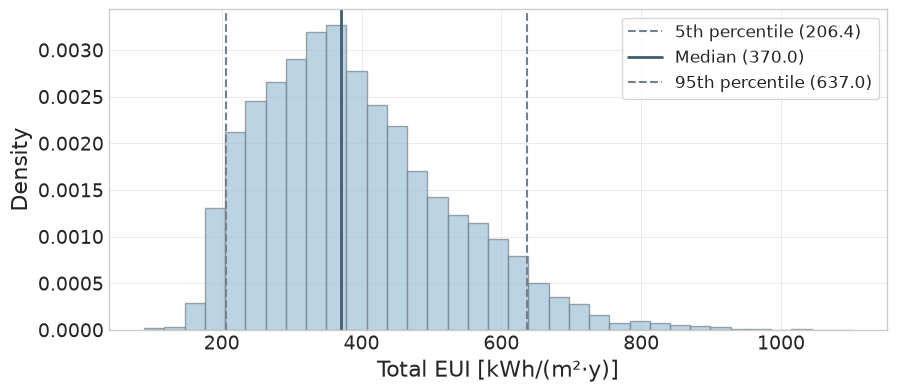

,statistic,kWh/(m2 y)
0,models,"13,260"
1,minimum,89.1
2,5th percentile,206.4
3,mean,390.5
4,median,370.0
5,95th percentile,637.0
6,maximum,1101.6
7,standard deviation,135.3


In [10]:
eui = labels_df[LABEL_COL]
eui_summary = dp.eui_distribution_summary(eui)
eui_summary.to_csv(PAPER_TABLES_DIR / "eui_distribution_statistics.csv", index=False)

fig = dp.plot_eui_distribution(eui)
path = PAPER_FIGURES_DIR / "eui_distribution_density.png"
fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="#ffffff")
print(f"figure -> {display_path(path)}")
show(fig)

eui_summary

## Is the target distributed the same way in train, val and test?

Histogram, empirical CDF, box plots and the rank-ordered tail. The histogram clips the top 0.5% of the
long tail into its last bin and states how much was clipped.

The table underneath carries the two-sample Kolmogorov-Smirnov test for train against val and
train against test: the statistic is the largest gap between their empirical CDFs, where 0 means
identically distributed, and a large p-value means no evidence that the splits differ.

**Outputs**: `outputs/figures/dataset/label_split_distributions.png`.

figure -> outputs/figures/dataset/label_split_distributions.png


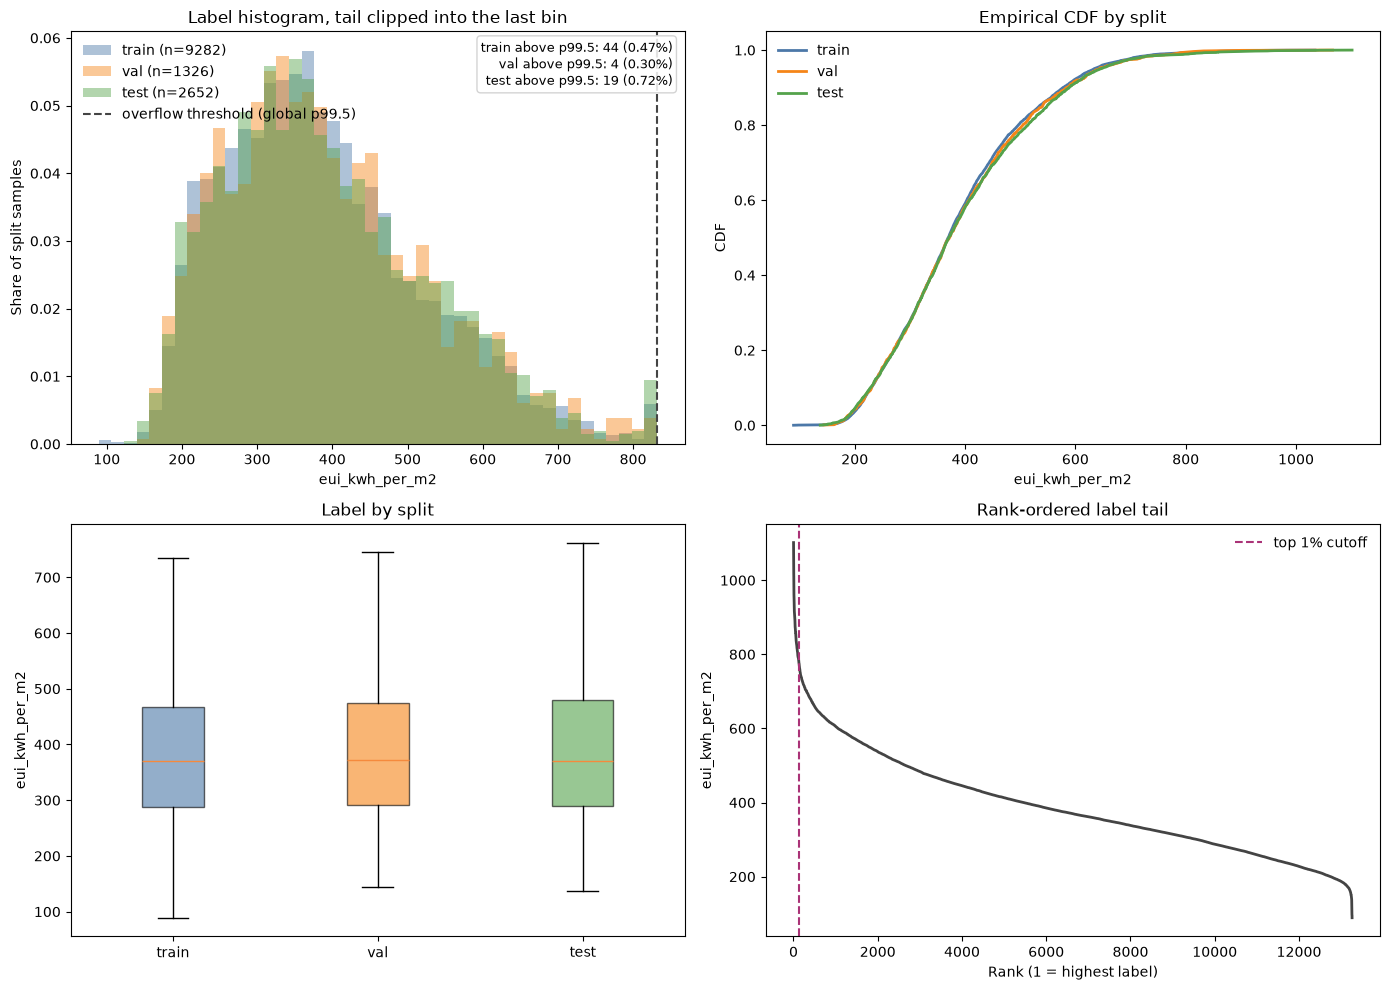

,split,n,mean,std,median,min,max
0,train,9282.0,389.0145,133.5128,369.4778,89.0750,1034.4306
1,val,1326.0,392.3390,136.6016,371.8375,144.1833,1066.1472
2,test,2652.0,394.6040,140.5737,370.3681,137.4944,1101.5694
3,KS_train_vs_val,NaN,0.0221,0.6172,NaN,NaN,NaN
4,KS_train_vs_test,NaN,0.0268,0.1011,NaN,NaN,NaN


In [11]:
fig = dp.plot_label_split_distributions(label_detail_df, label_col=LABEL_COL)
path = FIGURES_DIR / "label_split_distributions.png"
fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
print(f"figure -> {display_path(path)}")
show(fig)

label_split_df.round(4)

## How models and cities are spread across the splits

Sample and city counts per split, the composition of the thirty largest cities, and how many cities
appear in one, two or three splits.

Cities appear in several splits because the split is random over models.

**Outputs**: `outputs/figures/dataset/city_split_balance.png`.

figure -> outputs/figures/dataset/city_split_balance.png


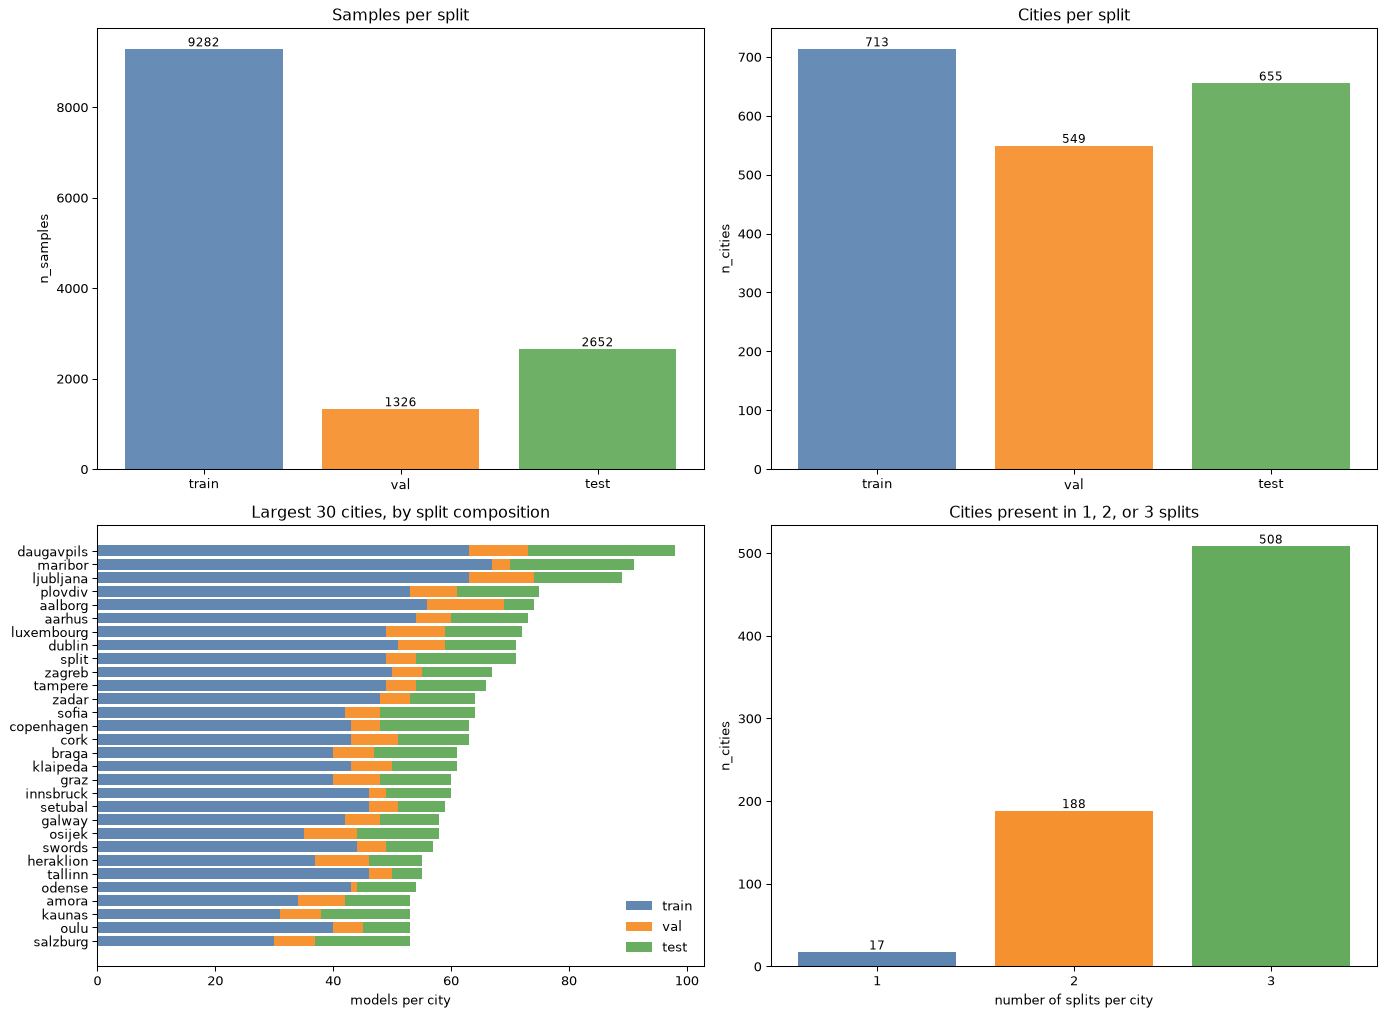

,city_key,test,train,val,total,single_split_only,n_splits_present,spans_splits,dominant_split,country,n_models
17,daugavpils,25,63,10,98,False,3,True,train,LVA,98
18,maribor,21,67,3,91,False,3,True,train,SVN,91
19,ljubljana,15,63,11,89,False,3,True,train,SVN,89
20,plovdiv,14,53,8,75,False,3,True,train,BGR,75
21,aalborg,5,56,13,74,False,3,True,train,DNK,74
22,aarhus,13,54,6,73,False,3,True,train,DNK,73
23,luxembourg,13,49,10,72,False,3,True,train,LUX,72
24,dublin,12,51,8,71,False,3,True,train,IRL,71


In [12]:
fig = dp.plot_city_split_balance(label_detail_df, city_assignment_df)
path = FIGURES_DIR / "city_split_balance.png"
fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
print(f"figure -> {display_path(path)}")
show(fig)

city_assignment_df.sort_values("total", ascending=False).head(8)

## Country coverage, and whether building size carries across

Countries per split, the composition of the largest twelve, and the size distribution from
`REPRESENTATIVE_SIZE_CONFIG` as a CDF and as box plots, to check that test buildings are not
systematically larger than training ones.

**Outputs**: `outputs/figures/dataset/country_and_size_balance.png`.

figure -> outputs/figures/dataset/country_and_size_balance.png


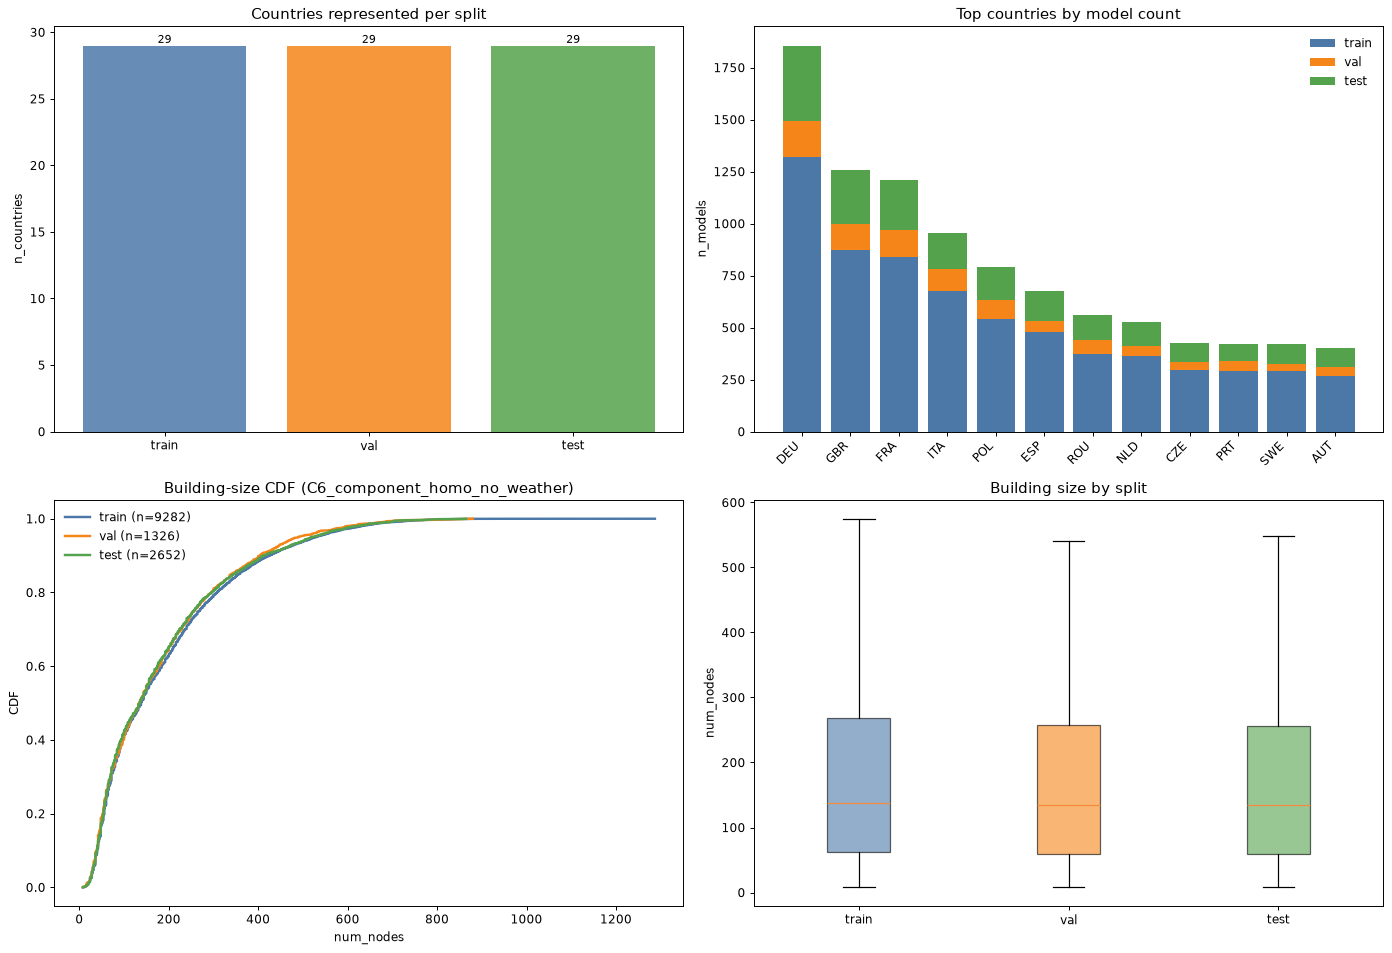

,country,train_cities,train_models,val_cities,val_models,test_cities,test_models,total_cities,total_models,n_splits_present
0,DEU,98,1321,84,170,95,365,98,1856,3
1,GBR,132,872,88,128,113,258,132,1258,3
2,FRA,70,839,59,129,64,240,70,1208,3
3,ITA,86,674,61,107,74,173,86,954,3
4,POL,61,541,43,90,56,159,61,790,3
5,ESP,70,479,35,51,59,145,70,675,3
6,ROU,25,374,23,66,25,120,25,560,3
7,NLD,39,362,30,51,37,115,39,528,3
8,CZE,13,295,13,38,13,91,13,424,3
9,PRT,8,291,8,48,8,81,8,420,3


In [13]:
fig = dp.plot_country_and_size_balance(
    country_split_df,
    # sizes from the manifest, available even when CONFIGS is narrowed
    size_frame,
    representative_size_config=REPRESENTATIVE_SIZE_CONFIG,
    group_assignments_df=split_result.group_assignments_df,
)
path = FIGURES_DIR / "country_and_size_balance.png"
fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
print(f"figure -> {display_path(path)}")
show(fig)

country_split_df.head(10)

## How far apart the ten configurations actually are

Mean node and edge counts on log axes, the full distributions per configuration, and the correlation
between the label and graph size.

A high label–size correlation would mean a model can score well by counting nodes.

**Outputs**: `outputs/figures/dataset/graph_config_overview.png`.

figure -> outputs/figures/dataset/graph_config_overview.png


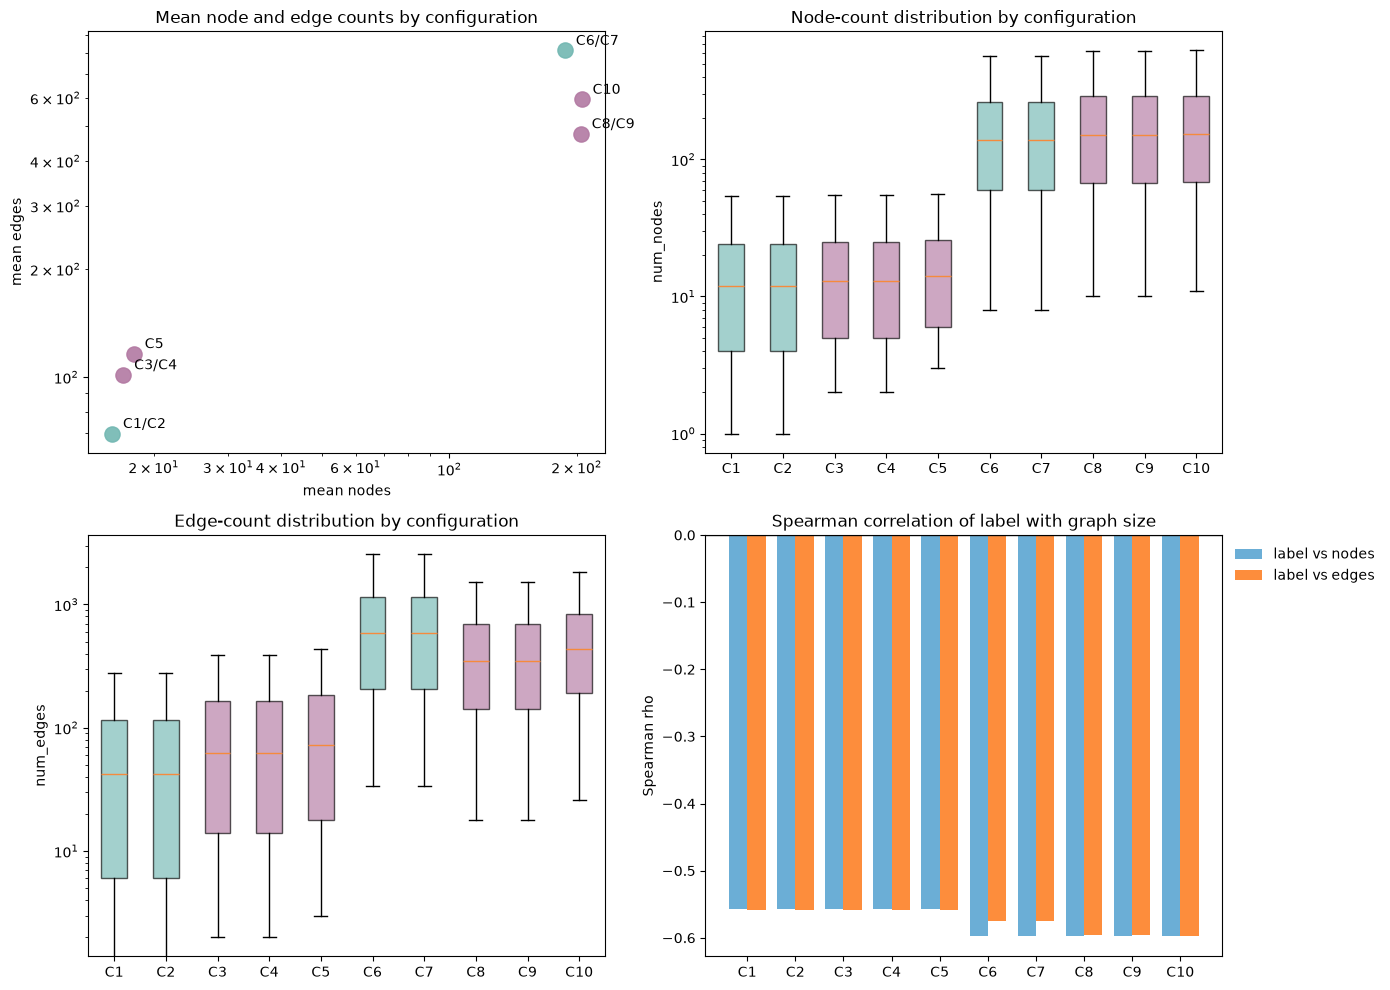

,config,graph_kind,label_vs_nodes_spearman,label_vs_edges_spearman
0,C1_zone_homo_no_weather,homo,-0.557,-0.558
1,C2_zone_homo_graph_weather,homo,-0.557,-0.558
2,C3_zone_hetero_no_weather,hetero,-0.557,-0.558
3,C4_zone_hetero_building_weather,hetero,-0.557,-0.558
4,C5_zone_hetero_external_weather,hetero,-0.557,-0.558
5,C6_component_homo_no_weather,homo,-0.598,-0.574
6,C7_component_homo_graph_weather,homo,-0.598,-0.574
7,C8_component_hetero_no_weather,hetero,-0.597,-0.596
8,C9_component_hetero_building_weather,hetero,-0.597,-0.596
9,C10_component_hetero_external_weather,hetero,-0.597,-0.597


In [14]:
fig = dp.plot_graph_config_overview(graph_size_summary_df, graph_detail_df, config_corr_df)
path = FIGURES_DIR / "graph_config_overview.png"
fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
print(f"figure -> {display_path(path)}")
show(fig)

config_corr_df.round(3)

## The label against graph size, one panel per distinct topology

Hexbin density over all 13,260 models.

**Outputs**: `outputs/figures/dataset/label_vs_graph_size.png`.

figure -> outputs/figures/dataset/label_vs_graph_size.png


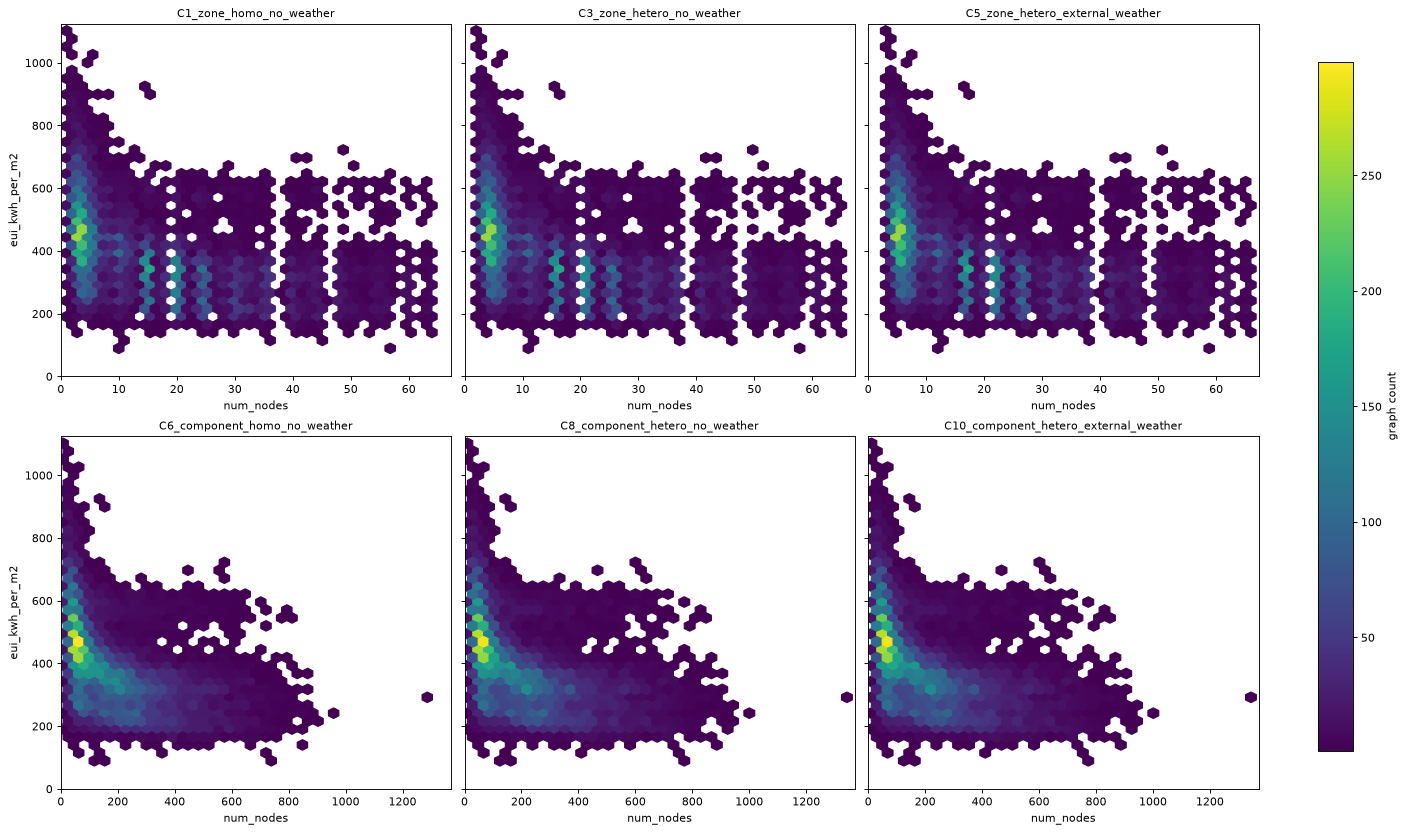

6 distinct topologies drawn


,config,graph_kind,nodes_mean,edges_mean
0,C10_component_hetero_external_weather,hetero,205.3,593.9
1,C1_zone_homo_no_weather,homo,15.9,69.6
3,C3_zone_hetero_no_weather,hetero,16.9,101.4
5,C5_zone_hetero_external_weather,hetero,17.9,116.1
6,C6_component_homo_no_weather,homo,187.4,812.8
8,C8_component_hetero_no_weather,hetero,204.3,476.3


In [15]:
from beg.report.topology_figure import distinct_topologies

representative_configs = [
    resolve(rep).full_name
    for rep, _ids in distinct_topologies()
    if resolve(rep).full_name in set(graph_detail_df["config"].cat.categories)
]

fig = dp.plot_label_vs_graph_size(
    graph_detail_df, label_col=LABEL_COL, configs=representative_configs
)
path = FIGURES_DIR / "label_vs_graph_size.png"
fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
print(f"figure -> {display_path(path)}")
show(fig)
print(f"{len(representative_configs)} distinct topologies drawn")

graph_size_summary_df.loc[
    graph_size_summary_df["config"].isin(representative_configs),
    ["config", "graph_kind", "nodes_mean", "edges_mean"],
].round(1)

# Readiness

### Check that BEG_04_Train can run

`BEG_04_Train` discovers packages by directory, reads only the small `.meta.json`, and hashes it into
a `dataset_fingerprint` that decides whether a run can be skipped or resumed. This checks it can do
all three, and that the ten packages received the same split.

**Outputs**: `readiness`, and a failure if anything downstream would break.

**Used functions**
`beg.train.runner.load_training_ready_packages`, `dataset_fingerprint`

In [16]:
from beg.train.runner import dataset_fingerprint, load_training_ready_packages

packages = load_training_ready_packages(DATASETS_OUT)
checks = []

checks.append(
    {"check": "one package per configuration", "ok": set(packages) == set(FULL_NAMES),
     "detail": f"{len(packages)} found, {len(FULL_NAMES)} expected"}
)

hashes = {cfg: p["metadata"]["split"]["train_ids_sha"] for cfg, p in packages.items()}
checks.append(
    {"check": "every package has the same split", "ok": len(set(hashes.values())) == 1,
     "detail": f"{len(set(hashes.values()))} distinct train-id hash(es)"}
)

sizes = {cfg: tuple(p["metadata"]["split_sizes"].values()) for cfg, p in packages.items()}
checks.append(
    {"check": "every package has the same sample count", "ok": len(set(sizes.values())) == 1,
     "detail": f"train/val/test {next(iter(sizes.values()))}"}
)

fingerprints = {cfg: dataset_fingerprint(p["metadata"]) for cfg, p in packages.items()}
checks.append(
    {"check": "every configuration fingerprints distinctly", "ok": len(set(fingerprints.values())) == len(packages),
     "detail": f"{len(set(fingerprints.values()))} distinct fingerprint(s)"}
)

checks.append(
    {"check": "labels carry their split", "ok": LABELS_WITH_SPLIT.exists(),
     "detail": display_path(LABELS_WITH_SPLIT)}
)

readiness = pd.DataFrame(checks)
if not readiness["ok"].all():
    print("NOT READY - resolve the failures above before running BEG_04_Train.")
else:
    print(f"Ready for BEG_04_Train: {len(packages)} packages, "
          f"{len(DATASET_IDS)} models, split {SPLIT['train_ids_sha'][:12]}.")

readiness

Ready for BEG_04_Train: 10 packages, 13260 models, split 07abe4f5af39.


,check,ok,detail
0,one package per configuration,True,"10 found, 10 expected"
1,every package has the same split,True,1 distinct train-id hash(es)
2,every package has the same sample count,True,"train/val/test (9282, 1326, 2652)"
3,every configuration fingerprints distinctly,True,10 distinct fingerprint(s)
4,labels carry their split,True,data/labels_with_split.csv


---

**Next:** `BEG_04_Train` reads these packages, combines each one's `dataset_fingerprint` with a
fingerprint of the model and training code, and trains only what has not been trained already.